# Stability of the Laplace–Beltrami spectrum (Phase 3, step 4)

**Question.** How far do eigenvalues move under the errors real data has, what can be proved about it, and does that explain the weak class signal found so far?

How to rerun: [`docs/reproductions/lb-stability.md`](../docs/reproductions/lb-stability.md). Surfaces are the size-matched ones from [`lb-roundness.ipynb`](lb-roundness.ipynb).

## 1. Theory

**Proposition (metric bound).** Let a surface deform so that, on each triangle or tangent plane, the map has singular values $s_1\ge s_2$. Let $E=\max s_1/s_2$, and let $a_{\min},a_{\max}$ bound the area factor $s_1s_2$. Then for every $k$,
$$\frac{1}{E\,a_{\max}}\le\frac{\lambda_k'}{\lambda_k}\le\frac{E}{a_{\min}}.$$
*Proof.* In two dimensions the Dirichlet energy density times area changes by a factor within $[1/E,E]$, and the mass by a factor within $[a_{\min},a_{\max}]$. So every Rayleigh quotient changes by at most these factors, and min-max carries that to every eigenvalue. The argument applies directly to piecewise-linear functions on triangles with lumped mass, so it holds exactly on our meshes. $\square$ This is a form of the quasi-isometry comparison in Dodziuk (1982).

Three things follow:

1. **The bound is relative and the same for every $k$.** A global stretch moves all eigenvalues by a similar proportion.
2. **Only metric change counts,** not how far points move, so rigid motion gives exactly 1.
3. **It is worst-case.** By the selection rule in `lb-roundness.ipynb`, a fine bump has no first-order effect on low modes, even though its slope widens the bound.

**Where it gives no protection: necks.** Two lobes joined by a thin neck have small $\lambda_1$, with $\lambda_1$ going to 0 as the neck closes (Cheeger's dumbbell). Making or breaking a neck changes connectivity, and no bound of this kind applies, because it needs a map between the surfaces with bounded distortion. Small boundary errors can do this, so $\lambda_1$ cannot be expected to be stable in general.

**Consequences for reliability.** Weyl's law makes all $\lambda_k\text{Area}$ approach $4\pi k$. So between-lesion spread shrinks as $k$ grows, and a small measurement error soon exceeds it. High modes can be stable in percent and still unreliable as features.

## 2. Implementation details

| Choice | Ours | Why |
|---|---|---|
| Surface | Size-matched: grid $V^{1/3}/24$, Gaussian $\sigma=0.04V^{1/3}$ | No size leak, from the previous step |
| Boundary noise | Threshold of signed distance plus smooth noise; 0.25, 0.5, 1 mm, length 1.5 mm, 3 draws | Assumed model of annotation error. Scale chosen by us, not measured |
| Resolution | Grid $V^{1/3}/16$ and $/32$ | Mesh dependence |
| Slices | Average over 2 and 4 slices along the 0.476 mm axis | Thicker scans |
| Real error | Zhou 2021 V-Net masks, 3 seeds, Test patches, against the patch's own true mask | Stored weights, read only; checksums unchanged. Patches are centred on the true lesion, which flatters the result |
| Misses | Masks too small to survive smoothing are recorded as missing | Listed below |
| Labels | Train+Validation only; Test used for geometry | Test stays clean |

ICC(1,1) on log values is the share of variance between lesions; below about 0.75 is commonly read as moderate reliability or worse.

## 3. Verification

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from abus_classification.features.shape_descriptor.shape_descriptors import lb_spectrum, spectrum_bound
from abus_classification.protocol import auc_ci
from abus_classification.utils.mesh import draw_mesh
from test.utils_tests.features_tests.test_signature import dumbbell, lobed_sphere

BLUE, ORANGE, AQUA, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
samples = np.load("../results/lb-stability/sample_meshes.npz")
def sample(key): return trimesh.Trimesh(samples[key + "_vertices"].astype(float), samples[key + "_faces"], process=False)
real = sample("malignant_clean"); ref = lb_spectrum(real, 21, False)[1:]; rows = {}
for name, v in {"Rotated": trimesh.transform_points(real.vertices, trimesh.transformations.rotation_matrix(1, [1, 2, 3])), "Stretched 2% along one axis": real.vertices * [1, 1, 1.02], "Stretched 10% along one axis": real.vertices * [1, 1, 1.1], "Scaled by 1.1": real.vertices * 1.1}.items():
    m = trimesh.Trimesh(v, real.faces, process=False); lo, hi = spectrum_bound(real, m); r = lb_spectrum(m, 21, False)[1:] / ref
    rows[name] = {"Bound, lower": lo, "Measured, lowest": r.min(), "Measured, highest": r.max(), "Bound, upper": hi}
display(pd.DataFrame(rows).T.round(4).style.format(precision=4).set_caption("λ'/λ on a real lesion mesh, k = 1–20"))
sphere = trimesh.creation.icosphere(subdivisions=6); s = lb_spectrum(sphere, 21)[1:]; rows = {}
for d in (2, 4, 8, 16, 24):
    m = lobed_sphere(d, 0.02); lo, hi = spectrum_bound(sphere, m); rows[f"d = {d}"] = {"Mean change, k = 1–20": np.abs(lb_spectrum(m, 21)[1:] / s - 1).mean(), "Bound width": hi - lo}
pd.DataFrame(rows).T.round(4)

,"Bound, lower","Measured, lowest","Measured, highest","Bound, upper"
Rotated,1.0000,1.0000,1.0000,1.0000
Stretched 2% along one axis,0.9612,0.9812,0.9930,1.0200
Stretched 10% along one axis,0.8264,0.9076,0.9667,1.1000
Scaled by 1.1,0.8264,0.8264,0.8264,0.8264


,"Mean change, k = 1–20",Bound width
d = 2,0.0085,0.0607
d = 4,0.0045,0.0601
d = 8,0.0013,0.0673
d = 16,0.0011,0.0974
d = 24,0.0017,0.1582


The bound holds on the real mesh. In the second table, every bump has the same amplitude: as degree rises the bound widens, while low modes change far less than it allows.

**The neck.** Each surface below is a closed dumbbell; the neck barely changes the volume and strongly changes $\lambda_1$.

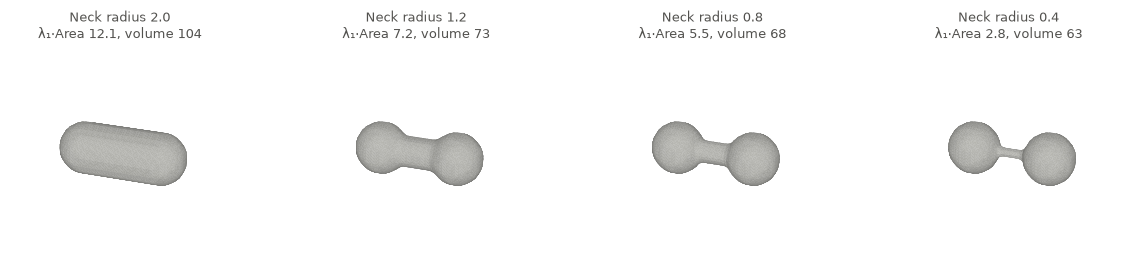

In [2]:
necks = (2.0, 1.2, 0.8, 0.4); fig = plt.figure(figsize=(12, 2.8))
for i, n in enumerate(necks):
    m = dumbbell(n); ax = fig.add_subplot(1, 4, i + 1, projection="3d"); draw_mesh(ax, m, view=(25, -70))
    ax.set_title(f"Neck radius {n}\nλ₁·Area {lb_spectrum(m, 3)[1]:.1f}, volume {m.volume:.0f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-necks.png", dpi=130); plt.show()

## 4. Results

### Simulated boundary noise on real lesions

The median-volume lesion of each class in Train, with increasing noise. The number is its $\lambda_1\cdot$Area for that one draw.

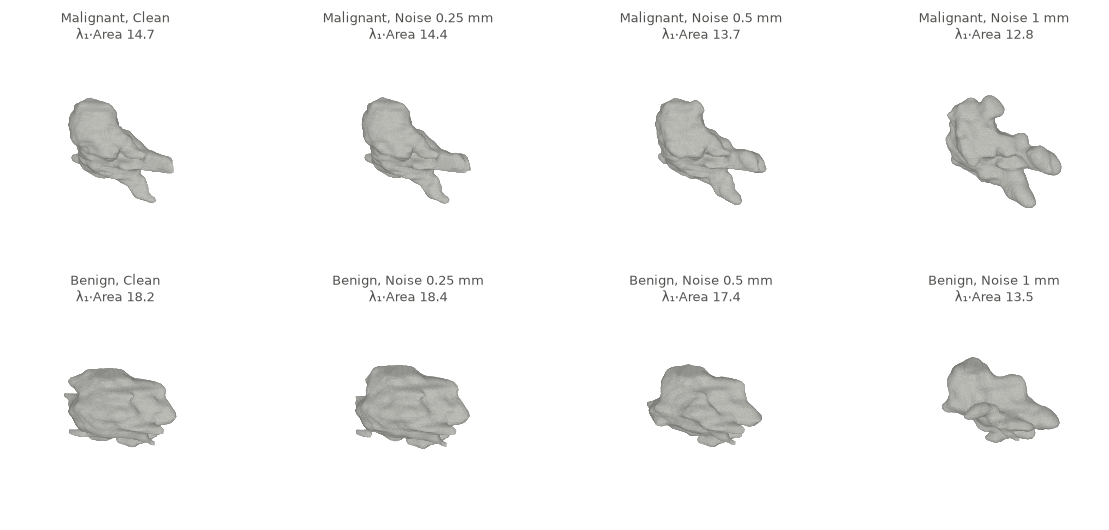

In [3]:
fig = plt.figure(figsize=(12, 5.4)); labels = [("clean", "Clean"), ("noise0.25", "Noise 0.25 mm"), ("noise0.5", "Noise 0.5 mm"), ("noise1.0", "Noise 1 mm")]
for row, cls in enumerate(("malignant", "benign")):
    for col, (key, name) in enumerate(labels):
        m = sample(f"{cls}_{key}"); ax = fig.add_subplot(2, 4, row * 4 + col + 1, projection="3d"); draw_mesh(ax, m)
        ax.set_title(f"{cls.capitalize()}, {name}\nλ₁·Area {lb_spectrum(m, 3)[1]:.1f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-noise.png", dpi=130); plt.show()

,0.25 mm,0.5 mm,1.0 mm
Median Dice with clean,0.989,0.922,0.784
Share genus 0,0.902,0.818,0.673
"ICC λ·Area, k=1",0.971,0.812,0.533
"ICC λ·Area, k=2",0.961,0.786,0.422
"ICC λ·Area, k=5",0.881,0.658,0.307
"ICC λ·Area, k=10",0.819,0.447,0.178
"ICC λ·Area, k=20",0.818,0.444,0.144
"ICC λ·Area, k=50",0.643,0.245,0.051
"ICC λ·Area, k=100",0.571,0.132,0.038
ICC elongation,0.978,0.911,0.695


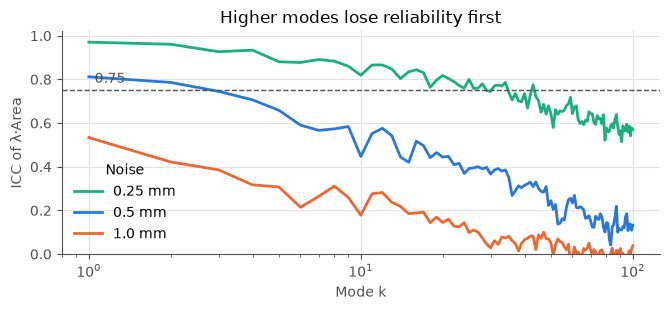

In [4]:
d = np.load("../results/lb-stability/spectra.npz"); R = list(map(str, d["renders"]))
lam, area, volume, euler, dice, extents = d["lam"], d["area"], d["volume"], d["euler"], d["dice"], np.sort(d["extents"], -1)
na = lam * area[..., None]; elong = extents[..., 2] / extents[..., 0]; sph = 36 * np.pi * volume ** 2 / area ** 3
def icc(x):
    x = np.log(x); m = x.shape[1]; g = x.mean(1); b = m * g.var(ddof=1); w = ((x - g[:, None]) ** 2).sum() / (x.shape[0] * (m - 1))
    return (b - w) / (b + (m - 1) * w)
amps = (0.25, 0.5, 1.0); I = {a: [0] + [R.index(f"noise {a} mm #{i}") for i in range(3)] for a in amps}; ks = (1, 2, 5, 10, 20, 50, 100)
display(pd.DataFrame({f"{a} mm": {"Median Dice with clean": np.nanmedian(dice[:, I[a][1:]]), "Share genus 0": (euler[:, I[a][1:]] == 2).mean(), **{f"ICC λ·Area, k={k}": icc(na[:, I[a], k]) for k in ks}, "ICC λ₁ shown above": icc(na[:, I[a], 1]), "ICC elongation": icc(elong[:, I[a]]), "ICC sphericity": icc(sph[:, I[a]]), "ICC volume": icc(volume[:, I[a]])} for a in amps}).drop("ICC λ₁ shown above").round(3).style.format(precision=3).set_caption("Reliability under boundary noise"))
fig, ax = plt.subplots(figsize=(6.8, 3.2)); k = np.arange(1, 101)
for a, c in zip(amps, (AQUA, BLUE, ORANGE)):
    y = [icc(na[:, I[a], i]) for i in k]; ax.plot(k, y, color=c, lw=2, label=f"{a} mm")
ax.axhline(0.75, color=INK, lw=1, ls="--"); ax.annotate("0.75", (1.05, 0.75), xytext=(0, 3), textcoords="offset points", va="bottom", color=INK)
ax.set(xscale="log", xlabel="Mode k", ylabel="ICC of λ·Area", ylim=(0, 1.02), title="Higher modes lose reliability first"); ax.legend(frameon=False, title="Noise", loc="lower left"); plt.tight_layout(); plt.savefig("../docs/assets/lb-icc.png", dpi=150); plt.show()

### Resolution and thicker slices

Median relative change against the clean surface. The last row is the between-lesion spread on the log scale, for comparison.

In [5]:
rows = {n: {f"k={k}": np.nanmedian(np.abs(na[:, R.index(n), k] / na[:, 0, k] - 1)) for k in ks} for n in ("grid 16", "grid 32", "slices x2", "slices x4")}
rows["Between-lesion SD"] = {f"k={k}": np.log(na[:, 0, k]).std() for k in ks}
pd.DataFrame(rows).T.round(3).style.format(precision=3)

,k=1,k=2,k=5,k=10,k=20,k=50,k=100
grid 16,0.015,0.016,0.016,0.014,0.012,0.011,0.022
grid 32,0.010,0.009,0.011,0.009,0.009,0.007,0.009
slices x2,0.019,0.019,0.021,0.018,0.014,0.008,0.005
slices x4,0.031,0.023,0.027,0.024,0.017,0.009,0.006
Between-lesion SD,0.255,0.162,0.100,0.052,0.030,0.012,0.007


### Real segmentation error

Three Test lesions at low, middle and high Dice for seed 0, with no class shown. The top row is the true mask's surface and the bottom row is the prediction's.

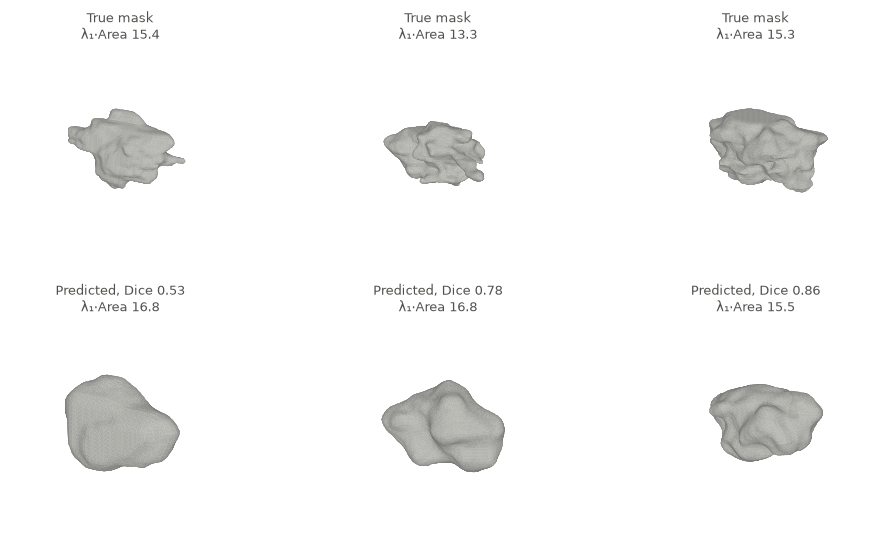

In [6]:
fig = plt.figure(figsize=(10, 5.6))
for col, name in enumerate(("low", "middle", "high")):
    for row, kind in enumerate(("truth", "predicted")):
        m = sample(f"{name}_{kind}"); ax = fig.add_subplot(2, 3, row * 3 + col + 1, projection="3d"); draw_mesh(ax, m)
        ax.set_title(f"{'True mask' if kind == 'truth' else 'Predicted, Dice ' + format(float(samples[name + '_dice']), '.2f')}\nλ₁·Area {lb_spectrum(m, 3)[1]:.1f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-predicted.png", dpi=130); plt.show()

In [7]:
p = np.load("../results/lb-stability/predicted.npz"); nap = p["lam"] * p["area"][..., None]; e = np.sort(p["extents"], -1); el = e[..., 2] / e[..., 0]
print("Mean Dice per seed:", p["dice"].mean(0).round(3), "stored seed 0 Dice:", np.load("../results/zhou2021/zhou2021_seed0_test.npz")["dice"].mean().round(3), "; missing surfaces per seed:", np.isnan(p["area"][:, 1:]).sum(0))
def compare(truth, pred):
    pairs = [spearmanr(truth, pred[:, s], nan_policy="omit")[0] for s in range(3)]
    return {"Spearman, true vs predicted, mean of seeds": np.mean(pairs), "Median relative error": np.nanmedian(np.abs(pred / truth[:, None] - 1))}
table = {"Volume": compare(p["volume"][:, 0], p["volume"][:, 1:]), "Elongation": compare(el[:, 0], el[:, 1:])}
table |= {f"λ·Area, k={k}": compare(nap[:, 0, k], nap[:, 1:, k]) for k in ks}
sp = 36 * np.pi * p["volume"] ** 2 / p["area"] ** 3
print("Median sphericity, 1 is a ball: true masks {:.3f}, predicted {:.3f}; predicted is rounder in {:.0%} of pairs".format(np.nanmedian(sp[:, 0]), np.nanmedian(sp[:, 1:]), np.nanmean(sp[:, 1:] > sp[:, [0]])))
table["Sphericity"] = compare(sp[:, 0], sp[:, 1:])
pd.DataFrame(table).T.round(3)

Mean Dice per seed: [0.724 0.74  0.734] stored seed 0 Dice: 0.724 ; missing surfaces per seed: [1 1 2]
Median sphericity, 1 is a ball: true masks 0.376, predicted 0.623; predicted is rounder in 94% of pairs


,"Spearman, true vs predicted, mean of seeds",Median relative error
Volume,0.920,0.214
Elongation,0.636,0.128
"λ·Area, k=1",0.402,0.156
"λ·Area, k=2",0.524,0.085
"λ·Area, k=5",0.367,0.070
"λ·Area, k=10",0.176,0.057
"λ·Area, k=20",-0.013,0.025
"λ·Area, k=50",-0.027,0.012
"λ·Area, k=100",-0.210,0.009
Sphericity,0.228,0.651


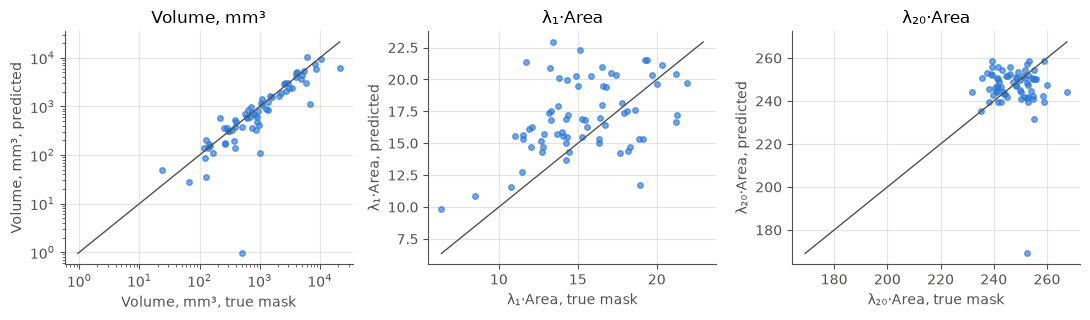

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
for a, x, y, name in ((ax[0], p["volume"][:, 0], p["volume"][:, 1], "Volume, mm³"), (ax[1], nap[:, 0, 1], nap[:, 1, 1], "λ₁·Area"), (ax[2], nap[:, 0, 20], nap[:, 1, 20], "λ₂₀·Area")):
    a.plot(x, y, "o", ms=4, color=BLUE, alpha=.65); lim = (np.nanmin([x, y]), np.nanmax([x, y])); a.plot(lim, lim, color=INK, lw=1); a.set(xlabel=f"{name}, true mask", ylabel=f"{name}, predicted", title=name)
ax[0].set(xscale="log", yscale="log"); plt.tight_layout(); plt.savefig("../docs/assets/lb-predicted-scatter.png", dpi=150); plt.show()

### Does the noise explain the weak signal?

Train+Validation only. If the simulated errors were destroying signal, the AUC should fall as noise rises. The true masks already carry unknown annotation error, so this cannot show what a perfect mask would give.

In [9]:
tv = ~d["test"]; y = d["y"][tv]
def cv(X):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return np.mean([roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="decision_function")) for s in range(10)])
rows = {}
for name, idx in [("Clean", [0])] + [(f"Noise {a} mm", I[a][1:]) for a in amps]:
    avg = lambda x: x[tv][:, idx].mean(1)
    rows[name] = {"λ₁·Area": roc_auc_score(y, avg(na[..., 1])), "Elongation, negated": roc_auc_score(y, -avg(elong)), "Volume": roc_auc_score(y, avg(volume)), "CV, λ·Area k≤20, one draw": cv(np.log(na[tv, idx[0], 1:21]))}
pd.DataFrame(rows).T.round(3)

,λ₁·Area,"Elongation, negated",Volume,"CV, λ·Area k≤20, one draw"
Clean,0.608,0.661,0.719,0.506
Noise 0.25 mm,0.606,0.653,0.720,0.511
Noise 0.5 mm,0.614,0.651,0.720,0.457
Noise 1.0 mm,0.589,0.564,0.714,0.568


## 5. Conclusions

- **The proved bound holds and is a worst case.** Metric change bounds every eigenvalue by the same ratio, and low modes move far less than it allows under fine bumps. Necks are the exception, where no such bound applies.
- **Percent error is misleading; reliability is the useful measure.** High modes change by only about 1%, yet between-lesion spread is just as small, so their ICC is lowest.
- **Under real segmentation error, a lesion's spectral rank mostly disappears.** Predicted masks preserve the volume rank well and elongation moderately. $\lambda_1$ keeps only a weak rank, and from $k=20$ up the rank is gone. These patches are centred on the true lesion, so real use would be no better. Predicted surfaces are also visibly smoother than true ones, so the network removes part of the irregularity that shape features would need; median sphericity rises from 0.38 to 0.62, and 94% of predictions are rounder than their true mask.
- **Simulated noise does not explain the weak class signal.** AUC stays about flat up to 0.5 mm, and at 1 mm mainly elongation falls. So stability is a separate limit: spectral features would be unreliable on predicted masks even if they had more signal. The mask's own annotation error remains untested.

## 6. Protocol

All 200 lesions for simulated errors; 70 Test patches for real segmentation, geometry only; labels on Train+Validation only. Malignant is positive. CPU for spectra; Zhou inference ran locally on Apple Silicon. No new training, no Kaggle kernel. Stored results: `results/lb-stability/`. The challenge benchmark does not apply.

## 7. Open issues

- **Noise scale.** The amplitudes are assumptions. Inter-observer data would calibrate them, and TDSC-ABUS has one annotation per lesion.
- **Predicted masks on full volumes.** Zhou's patches use the true centre, so the error here is a lower bound for an automatic pipeline.
- **Stable descriptors.** A descriptor designed from these results should weigh modes by reliability. The next steps, spherical harmonics and theory-driven descriptors, can test this.